# KA SS 26 · Challenge 2 — Cell Instance Segmentation
## Stage 2: full single-model Mask R-CNN run

This notebook is designed for **Kaggle T4×2 with one GPU exposed**, AMP enabled, and no ensembling.

It incorporates the Stage 1 findings:

- official metric = mean per-image **instance F1**, with greedy one-to-one matching at mask Dice ≥ 0.50;
- 424 train / 182 test / 1,972 unlabeled images, 520×704;
- instance counts are extremely variable (p95 ≈ 504, max 782);
- the supplied 100-detection cap is far too small;
- RLE is C-order;
- anchors must be derived in the **resized-image coordinate system**;
- validation, checkpoint selection, and threshold tuning must optimize the official F1.

### Before running

1. Use a Kaggle GPU session with **T4×2**. The notebook exposes only GPU 0.
2. Keep Internet on if torchvision must download COCO weights.
3. Use **Save Version → Save & Run All** so the run can continue headlessly.
4. The final file to submit is `/kaggle/working/submission.csv`.
5. Expected total time is usually several hours, not necessarily the full budget. A wall-clock guard preserves time for validation sweep and submission generation.


## 0 · Environment, deterministic setup, and output directories


In [5]:
import os

# Must be set before torch is imported. Kaggle may allocate T4 x2; this run uses only cuda:0.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTHONHASHSEED"] = "42"

import sys
import gc
import json
import time
import math
import random
import warnings
import shutil
from glob import glob
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
import torchvision

warnings.filterwarnings("ignore")
T_START = time.time()

def elapsed_seconds():
    return time.time() - T_START

def format_duration(seconds):
    seconds = int(seconds)
    return f"{seconds // 3600}h {(seconds % 3600) // 60:02d}m"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
torch.backends.cudnn.benchmark = True

try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ART = Path("/kaggle/working/artifacts")
CKPT = Path("/kaggle/working/checkpoints")
ART.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)

print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("device      :", DEVICE)
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("gpu         :", torch.cuda.get_device_name(0))
    print("gpu memory  :", f"{props.total_memory / 1e9:.1f} GB")
print("cpu count   :", os.cpu_count())


python      : 3.12.13
torch       : 2.10.0+cu128
torchvision : 0.25.0+cu128
device      : cuda
gpu         : Tesla T4
gpu memory  : 15.6 GB
cpu count   : 4


## 1 · Configuration


In [6]:
class CFG:
    # Run
    SEED = 42
    SMOKE_TEST = False
    TOTAL_BUDGET_SEC = 10.0 * 3600
    RESERVE_SEC = 45 * 60

    # Data
    VAL_FRACTION = 0.15
    IMG_H = 520
    IMG_W = 704
    RLE_ORDER = "auto"
    MIN_GT_AREA = 10
    MAX_INSTANCES_TRAIN = 600

    # Official metric
    PRIMARY_METRIC = "f1"
    DICE_MATCH_THR = 0.50

    # Model
    ARCH = "v2"
    WEIGHTS_MODE = "coco"  # official baseline also uses COCO detector weights
    TRAINABLE_BACKBONE_LAYERS = 5
    MIN_SIZE_TRAIN = (704, 768, 800, 864)
    MIN_SIZE_TEST = 800
    MAX_SIZE = 1400
    NORMALIZE_WITH_DATASET_STATS = False  # False preserves pretrained ImageNet normalization

    # Filled from EDA
    ANCHOR_SIZES = "auto"
    ASPECT_RATIOS = "auto"
    ANCHOR_SCALE_CORRECTION = True
    BOX_DET_PER_IMG = 850
    CACHE_MAX_DET = None
    EVAL_MAX_DET = None

    # Detection internals
    RPN_PRE_TEST = 4000
    RPN_POST_TEST = 2500
    RPN_BATCH_PER_IMG = 512
    BOX_BATCH_PER_IMG = 512
    BOX_NMS_THR = 0.60

    # Loss
    MASK_LOSS = "bce+dice"
    BCE_W = 1.0
    DICE_W = 1.0

    # Optimization
    EPOCHS = 26
    BATCH_SIZE = 2
    ACCUM_STEPS = 2
    LR = 1.5e-4
    BACKBONE_LR_MULT = 0.5
    WEIGHT_DECAY = 1e-4
    WARMUP_STEPS = 250
    GRAD_CLIP = 5.0
    AMP = True
    NUM_WORKERS = 2

    # Evaluation schedule
    EVAL_START_EPOCH = 3
    EVAL_EVERY_EARLY = 3
    EVAL_DENSE_FROM = 20
    EVAL_SCORE_GRID = tuple(np.round(np.arange(0.10, 0.91, 0.10), 2))
    EVAL_MASK_THR = 0.50
    EVAL_MIN_AREA = 50

    # Augmentation
    AUG_HFLIP = 0.5
    AUG_VFLIP = 0.5
    AUG_ROT90 = 0.5
    AUG_BRIGHTNESS_CONTRAST = 0.5
    AUG_GAMMA = 0.3
    AUG_NOISE = 0.2

    # Final cache and sweep
    CACHE_SCORE_THR = 0.01
    SWEEP_MASK_THR = (0.30, 0.40, 0.50, 0.60)
    SWEEP_SCORE_THR = tuple(np.round(np.arange(0.02, 0.99, 0.02), 2))
    SWEEP_MIN_AREA_Q = (0.00, 0.01, 0.03, 0.06, 0.10)
    SWEEP_ALLOW_OVERLAP = (False, True)

    # Image-cluster thresholding
    CLUSTER_K_RANGE = (2, 3, 4, 5)
    PER_CLUSTER_THRESHOLDS = "auto"
    PER_CLUSTER_MIN_VAL = 10
    PER_CLUSTER_MIN_GAIN = 0.010

    # Submission
    SUB_INDEX_COL = "idx"
    FALLBACK_TO_TOP_DETECTION = True

if CFG.SMOKE_TEST:
    CFG.EPOCHS = 2
    CFG.EVAL_START_EPOCH = 1
    CFG.EVAL_EVERY_EARLY = 1
    CFG.EVAL_DENSE_FROM = 1
    CFG.MIN_SIZE_TRAIN = (704,)
    CFG.SWEEP_MASK_THR = (0.40, 0.50)
    CFG.SWEEP_SCORE_THR = tuple(np.round(np.arange(0.10, 0.91, 0.10), 2))
    CFG.SWEEP_MIN_AREA_Q = (0.00, 0.05)
    CFG.SWEEP_ALLOW_OVERLAP = (False,)

seed_everything(CFG.SEED)
STATS = {}

print("SMOKE_TEST    :", CFG.SMOKE_TEST)
print("epochs        :", CFG.EPOCHS)
print("primary metric:", CFG.PRIMARY_METRIC)
print("time budget   :", format_duration(CFG.TOTAL_BUDGET_SEC))


SMOKE_TEST    : False
epochs        : 26
primary metric: f1
time budget   : 10h 00m


## 2 · Dataset discovery and schema validation


In [7]:
from PIL import Image

def find_dataset_root():
    roots = []
    for csv_path in Path("/kaggle/input").rglob("train.csv"):
        root = csv_path.parent
        if (root / "train").is_dir() and (root / "test").is_dir():
            roots.append(root)
    if not roots:
        raise FileNotFoundError(
            "Could not find a directory containing train.csv, train/, and test/ under /kaggle/input"
        )
    roots = sorted(set(roots), key=lambda p: (len(str(p)), str(p)))
    print("dataset candidates:")
    for r in roots:
        print(" ", r)
    return roots[0]

BASE = find_dataset_root()
TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"
UNLAB_DIR = BASE / "unlabeled_additional_data"
TRAIN_CSV = BASE / "train.csv"

print("\nselected BASE:", BASE)
print("contents:")
for p in sorted(BASE.iterdir()):
    if p.is_dir():
        print(f"  [dir ] {p.name:<32} {len(list(p.glob('*')))} files")
    else:
        print(f"  [file] {p.name:<32} {p.stat().st_size / 1e6:.2f} MB")

sample_candidates = list(BASE.glob("*submission*.csv")) + list(Path("/kaggle/input").rglob("*sample_submission*.csv"))
SAMPLE_SUB = sample_candidates[0] if sample_candidates else None
if SAMPLE_SUB:
    sample_df = pd.read_csv(SAMPLE_SUB)
    print("\nsample submission:", SAMPLE_SUB)
    print("columns:", sample_df.columns.tolist(), "rows:", len(sample_df))
    print(sample_df.head(3).to_string())
else:
    print("\nNo sample submission found. The notebook will use idx, id, annotation.")


dataset candidates:
  /kaggle/input/competitions/ka-ss-26-challenge-2/cells_segmentation

selected BASE: /kaggle/input/competitions/ka-ss-26-challenge-2/cells_segmentation
contents:
  [dir ] test                             182 files
  [dir ] train                            424 files
  [file] train.csv                        13.35 MB
  [dir ] unlabeled_additional_data        1972 files

No sample submission found. The notebook will use idx, id, annotation.


In [8]:
df_raw = pd.read_csv(TRAIN_CSV)
print("shape  :", df_raw.shape)
print("columns:", df_raw.columns.tolist())
print("dtypes :\n", df_raw.dtypes.to_string())
print("\nhead:\n", df_raw.head(3).to_string())

ID_COL = next(
    (c for c in df_raw.columns if c.lower() in ("id", "image_id", "imageid")),
    None,
)
ANN_COL = next(
    (c for c in df_raw.columns if c.lower() in ("annotation", "encodedpixels", "rle", "segmentation")),
    None,
)
assert ID_COL is not None and ANN_COL is not None, (
    f"Could not identify id and annotation columns in {df_raw.columns.tolist()}"
)

OTHER_COLS = [c for c in df_raw.columns if c not in (ID_COL, ANN_COL)]
CELL_TYPE_COL = next(
    (
        c
        for c in OTHER_COLS
        if df_raw[c].dtype == object and 1 < df_raw[c].nunique(dropna=True) <= 12
    ),
    None,
)
HAS_CELL_TYPE = CELL_TYPE_COL is not None

print("\nID_COL       :", ID_COL)
print("ANN_COL      :", ANN_COL)
print("other columns:", OTHER_COLS)
print("cell type    :", CELL_TYPE_COL)
print("unique images:", df_raw[ID_COL].nunique())
print("annotation rows:", len(df_raw))

STATS["csv_columns"] = df_raw.columns.tolist()
STATS["has_cell_type"] = bool(HAS_CELL_TYPE)
STATS["n_annotations"] = int(len(df_raw))
STATS["n_train_images"] = int(df_raw[ID_COL].nunique())


shape  : (53065, 3)
columns: ['Unnamed: 0', 'id', 'annotation']
dtypes :
 Unnamed: 0     int64
id            object
annotation    object

head:
    Unnamed: 0            id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

In [9]:
def folder_report(folder, inspect_all=True):
    files = sorted(folder.glob("*.png"))
    probe = files if inspect_all else files[:200]
    sizes = Counter()
    for path in probe:
        with Image.open(path) as im:
            sizes[(im.size[1], im.size[0])] += 1
    return files, sizes

train_files, train_sizes = folder_report(TRAIN_DIR)
test_files, test_sizes = folder_report(TEST_DIR)
if UNLAB_DIR.exists():
    unlab_files, unlab_sizes = folder_report(UNLAB_DIR, inspect_all=False)
else:
    unlab_files, unlab_sizes = [], Counter()

for name, files, sizes in [
    ("train", train_files, train_sizes),
    ("test", test_files, test_sizes),
    ("unlabeled", unlab_files, unlab_sizes),
]:
    print(f"{name:<10} {len(files):>5} images | sizes(H,W): {dict(sizes)}")

assert len(train_sizes) == 1, f"Mixed train image sizes: {train_sizes}"
assert len(test_sizes) == 1, f"Mixed test image sizes: {test_sizes}"
(H, W), _ = train_sizes.most_common(1)[0]
CFG.IMG_H, CFG.IMG_W = int(H), int(W)

TRAIN_IDS = sorted(path.stem for path in train_files)
TEST_IDS = sorted(path.stem for path in test_files)

STATS["img_hw"] = [CFG.IMG_H, CFG.IMG_W]
STATS["n_test_images"] = len(TEST_IDS)
STATS["n_unlabeled"] = len(list(UNLAB_DIR.glob("*.png"))) if UNLAB_DIR.exists() else 0

print("\nresolved shape:", (CFG.IMG_H, CFG.IMG_W))

# A harmless placeholder ensures that a failed commit still exposes a CSV.
placeholder = pd.DataFrame(
    {
        CFG.SUB_INDEX_COL: np.arange(len(TEST_IDS)),
        ID_COL: TEST_IDS,
        ANN_COL: ["-1"] * len(TEST_IDS),
    }
)
placeholder.to_csv("/kaggle/working/submission.csv", index=False)
print("placeholder /kaggle/working/submission.csv written; it will be overwritten after inference")


train        424 images | sizes(H,W): {(520, 704): 424}
test         182 images | sizes(H,W): {(520, 704): 182}
unlabeled   1972 images | sizes(H,W): {(520, 704): 200}

resolved shape: (520, 704)
placeholder /kaggle/working/submission.csv written; it will be overwritten after inference


## 3 · RLE order detection, round-trip validation, and annotation cache


In [10]:
from scipy import ndimage as ndi

def rle_decode_flat(rle, h, w, order="C"):
    if not isinstance(rle, str) or not rle.strip() or rle.strip() == "-1":
        return np.empty(0, dtype=np.int64)

    values = np.fromstring(rle, sep=" ", dtype=np.int64)
    if values.size % 2 != 0:
        raise ValueError("RLE must contain start/length pairs")

    starts = values[0::2] - 1
    lengths = values[1::2]
    parts = [np.arange(start, start + length, dtype=np.int64) for start, length in zip(starts, lengths)]
    idx = np.concatenate(parts) if parts else np.empty(0, dtype=np.int64)

    if order == "C":
        return idx

    # Convert Fortran-linear indices to row-major indices.
    return (idx % h) * w + (idx // h)

def rle_encode(mask_bool):
    pixels = np.asarray(mask_bool, dtype=np.uint8).reshape(-1)
    padded = np.concatenate(([0], pixels, [0]))
    runs = np.flatnonzero(padded[1:] != padded[:-1]) + 1
    runs[1::2] -= runs[0::2]
    return " ".join(map(str, runs.tolist()))

def flat_to_mask(flat, h, w):
    mask = np.zeros(h * w, dtype=bool)
    mask[np.asarray(flat, dtype=np.int64)] = True
    return mask.reshape(h, w)

valid_rows = df_raw[
    df_raw[ANN_COL].notna()
    & (df_raw[ANN_COL].astype(str).str.strip() != "")
    & (df_raw[ANN_COL].astype(str).str.strip() != "-1")
]
probe = valid_rows.sample(min(300, len(valid_rows)), random_state=CFG.SEED)

order_report = {}
for order in ("C", "F"):
    components = []
    fill_ratios = []
    out_of_bounds = 0

    for rle in probe[ANN_COL].astype(str):
        flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, order)
        if flat.size == 0:
            continue
        if flat.min() < 0 or flat.max() >= CFG.IMG_H * CFG.IMG_W:
            out_of_bounds += 1
            continue

        mask = flat_to_mask(flat, CFG.IMG_H, CFG.IMG_W)
        _, n_components = ndi.label(mask)
        components.append(n_components)

        ys, xs = np.nonzero(mask)
        box_area = (ys.max() - ys.min() + 1) * (xs.max() - xs.min() + 1)
        fill_ratios.append(mask.sum() / max(box_area, 1))

    order_report[order] = {
        "mean_components": float(np.mean(components)),
        "pct_single_component": float(np.mean(np.asarray(components) == 1) * 100),
        "mean_fill_ratio": float(np.mean(fill_ratios)),
        "out_of_bounds": int(out_of_bounds),
    }

print(pd.DataFrame(order_report).T.to_string())

if CFG.RLE_ORDER == "auto":
    CFG.RLE_ORDER = max(
        order_report,
        key=lambda order: (
            order_report[order]["pct_single_component"],
            order_report[order]["mean_fill_ratio"],
        ),
    )

print("\nRLE_ORDER:", CFG.RLE_ORDER)

probe_rle = str(probe.iloc[0][ANN_COL])
probe_flat = rle_decode_flat(probe_rle, CFG.IMG_H, CFG.IMG_W, CFG.RLE_ORDER)
probe_mask = flat_to_mask(probe_flat, CFG.IMG_H, CFG.IMG_W)
round_trip = rle_decode_flat(rle_encode(probe_mask), CFG.IMG_H, CFG.IMG_W, "C")
assert np.array_equal(np.sort(probe_flat), np.sort(round_trip)), "RLE round-trip failed"

STATS["rle_order_report"] = order_report
STATS["rle_order"] = CFG.RLE_ORDER
print("round-trip: passed")


   mean_components  pct_single_component  mean_fill_ratio  out_of_bounds
C         1.643333             94.333333         0.574928            0.0
F        27.003333              0.000000         0.018967            0.0

RLE_ORDER: C
round-trip: passed


In [11]:
t0 = time.time()
INST = defaultdict(list)
bad_rows = 0

for image_id, rle in zip(df_raw[ID_COL].astype(str), df_raw[ANN_COL].astype(str)):
    rle = rle.strip()
    if rle in ("", "-1", "nan"):
        continue
    try:
        flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, CFG.RLE_ORDER)
    except Exception:
        bad_rows += 1
        continue
    if flat.size == 0 or flat.min() < 0 or flat.max() >= CFG.IMG_H * CFG.IMG_W:
        bad_rows += 1
        continue
    INST[image_id].append(flat.astype(np.int32))

print(
    f"decoded {sum(len(v) for v in INST.values())} instances "
    f"across {len(INST)} images in {time.time() - t0:.1f}s; bad/skipped={bad_rows}"
)

overlap_image_count = 0
overlap_fractions = []
overlap_probe_ids = list(INST)[:120]
for image_id in overlap_probe_ids:
    accumulator = np.zeros(CFG.IMG_H * CFG.IMG_W, dtype=np.int16)
    for flat in INST[image_id]:
        accumulator[flat] += 1
    overlap_pixels = int((accumulator > 1).sum())
    overlap_image_count += int(overlap_pixels > 0)
    foreground_pixels = max(int((accumulator > 0).sum()), 1)
    overlap_fractions.append(overlap_pixels / foreground_pixels)

overlap_pct = 100 * overlap_image_count / max(len(overlap_probe_ids), 1)
print(f"images with GT overlap in probe: {overlap_pct:.1f}%")
print(f"mean overlap fraction of foreground: {100 * np.mean(overlap_fractions):.3f}%")

STATS["gt_overlap_images_pct"] = float(overlap_pct)
STATS["gt_overlap_fg_fraction"] = float(np.mean(overlap_fractions))


decoded 53065 instances across 424 images in 3.2s; bad/skipped=0
images with GT overlap in probe: 91.7%
mean overlap fraction of foreground: 1.128%


## 4 · EDA-driven detection capacity, areas, and resize-corrected anchors


In [12]:
counts = np.asarray([len(INST[image_id]) for image_id in TRAIN_IDS if image_id in INST])
areas = []
box_widths = []
box_heights = []

for instances in INST.values():
    for flat in instances:
        ys, xs = np.divmod(flat, CFG.IMG_W)
        areas.append(flat.size)
        box_widths.append(xs.max() - xs.min() + 1)
        box_heights.append(ys.max() - ys.min() + 1)

areas = np.asarray(areas)
box_widths = np.asarray(box_widths)
box_heights = np.asarray(box_heights)
box_side = np.sqrt(box_widths.astype(float) * box_heights)
aspect = box_heights / np.maximum(box_widths, 1)

def percentile_report(values, percentiles=(0, 1, 5, 25, 50, 75, 95, 99, 100)):
    return {
        f"p{p}": float(np.percentile(values, p))
        for p in percentiles
    }

print("instances per image:", {k: round(v, 1) for k, v in percentile_report(counts).items()})
print("instance area      :", {k: round(v, 1) for k, v in percentile_report(areas).items()})
print("box sqrt(w*h)      :", {k: round(v, 1) for k, v in percentile_report(box_side).items()})
print("aspect h/w         :", {k: round(v, 2) for k, v in percentile_report(aspect).items()})

STATS["counts"] = percentile_report(counts)
STATS["areas"] = percentile_report(areas)
STATS["box_side"] = percentile_report(box_side)
STATS["aspect"] = percentile_report(aspect)

# p99 × 1.4, rounded to 50, with an upper safety limit.
derived_cap = int(np.ceil(np.percentile(counts, 99) * 1.4 / 50) * 50)
CFG.BOX_DET_PER_IMG = int(np.clip(derived_cap, 300, 1000))
CFG.CACHE_MAX_DET = CFG.BOX_DET_PER_IMG if CFG.CACHE_MAX_DET is None else CFG.CACHE_MAX_DET
CFG.EVAL_MAX_DET = CFG.BOX_DET_PER_IMG if CFG.EVAL_MAX_DET is None else CFG.EVAL_MAX_DET

print(
    f"\nBOX_DET_PER_IMG = CACHE_MAX_DET = EVAL_MAX_DET = {CFG.BOX_DET_PER_IMG} "
    f"(p95={np.percentile(counts, 95):.0f}, p99={np.percentile(counts, 99):.0f}, max={counts.max()})"
)

# Anchors are generated after GeneralizedRCNNTransform resizes the image.
train_scales = [
    min(size / CFG.IMG_H, CFG.MAX_SIZE / CFG.IMG_W)
    for size in CFG.MIN_SIZE_TRAIN
]
scale_train = float(np.median(train_scales))
scale_test = float(min(CFG.MIN_SIZE_TEST / CFG.IMG_H, CFG.MAX_SIZE / CFG.IMG_W))
anchor_scale = 0.5 * (scale_train + scale_test) if CFG.ANCHOR_SCALE_CORRECTION else 1.0

if CFG.ANCHOR_SIZES == "auto":
    raw_sizes = np.percentile(box_side, [8, 25, 50, 78, 96])
    resized_sizes = raw_sizes * anchor_scale
    sizes = [int(max(8, round(size / 4) * 4)) for size in resized_sizes]
    for i in range(1, len(sizes)):
        sizes[i] = max(sizes[i], sizes[i - 1] + 4)
    CFG.ANCHOR_SIZES = tuple((size,) for size in sizes)

if CFG.ASPECT_RATIOS == "auto":
    lo, hi = np.percentile(aspect, [15, 85])
    CFG.ASPECT_RATIOS = (
        float(round(max(0.2, min(lo, 0.8)), 2)),
        1.0,
        float(round(min(5.0, max(hi, 1.25)), 2)),
    )

MIN_AREA_GRID = sorted(
    set(int(np.percentile(areas, q * 100)) for q in CFG.SWEEP_MIN_AREA_Q)
)

print(f"resize scale train≈{scale_train:.3f}, test≈{scale_test:.3f}, anchor scale={anchor_scale:.3f}")
print("ANCHOR_SIZES  :", CFG.ANCHOR_SIZES)
print("ASPECT_RATIOS :", CFG.ASPECT_RATIOS)
print("min-area grid :", MIN_AREA_GRID)

STATS["anchor_scale"] = float(anchor_scale)
STATS["anchor_sizes"] = str(CFG.ANCHOR_SIZES)
STATS["aspect_ratios"] = str(CFG.ASPECT_RATIOS)


instances per image: {'p0': 5.0, 'p1': 11.0, 'p5': 17.0, 'p25': 29.0, 'p50': 47.5, 'p75': 144.2, 'p95': 503.8, 'p99': 592.8, 'p100': 782.0}
instance area      : {'p0': 30.0, 'p1': 53.0, 'p5': 82.0, 'p25': 145.0, 'p50': 215.0, 'p75': 341.0, 'p95': 920.0, 'p99': 2123.4, 'p100': 13327.0}
box sqrt(w*h)      : {'p0': 6.0, 'p1': 8.9, 'p5': 11.0, 'p25': 15.0, 'p50': 18.8, 'p75': 25.5, 'p95': 54.1, 'p99': 89.4, 'p100': 314.4}
aspect h/w         : {'p0': 0.02, 'p1': 0.29, 'p5': 0.44, 'p25': 0.74, 'p50': 1.0, 'p75': 1.33, 'p95': 2.21, 'p99': 3.34, 'p100': 12.56}

BOX_DET_PER_IMG = CACHE_MAX_DET = EVAL_MAX_DET = 850 (p95=504, p99=593, max=782)
resize scale train≈1.508, test≈1.538, anchor scale=1.523
ANCHOR_SIZES  : ((20,), (24,), (28,), (40,), (92,))
ASPECT_RATIOS : (0.62, 1.0, 1.58)
min-area grid : [30, 53, 71, 87, 103]


In [13]:
def load_gray01(path):
    with Image.open(path) as image:
        return np.asarray(image.convert("L"), dtype=np.float32) / 255.0

def image_features(path):
    with Image.open(path) as image:
        arr = np.asarray(image.convert("L"), dtype=np.float32)

    histogram = np.histogram(arr, bins=24, range=(0, 255))[0].astype(np.float32)
    histogram /= max(histogram.sum(), 1)
    laplacian = ndi.laplace(arr)

    summary = np.asarray(
        [
            arr.mean(),
            arr.std(),
            np.percentile(arr, 1),
            np.percentile(arr, 25),
            np.percentile(arr, 50),
            np.percentile(arr, 75),
            np.percentile(arr, 99),
            laplacian.var(),
            np.abs(np.diff(arr, axis=0)).mean(),
            np.abs(np.diff(arr, axis=1)).mean(),
        ],
        dtype=np.float32,
    )
    return np.concatenate([summary, histogram])

t0 = time.time()
FEATURES = {}
for path in train_files + test_files:
    FEATURES[path.stem] = image_features(path)
print(f"computed image features for {len(FEATURES)} train+test images in {time.time() - t0:.1f}s")

pixel_sum = 0.0
pixel_sq_sum = 0.0
pixel_count = 0
for path in train_files[:200]:
    arr = load_gray01(path).astype(np.float64)
    pixel_sum += arr.sum()
    pixel_sq_sum += np.square(arr).sum()
    pixel_count += arr.size

DS_MEAN = float(pixel_sum / pixel_count)
DS_STD = float(np.sqrt(max(pixel_sq_sum / pixel_count - DS_MEAN ** 2, 1e-12)))
print(f"dataset mean/std: {DS_MEAN:.4f}/{DS_STD:.4f}")
print("model normalization:", "dataset statistics" if CFG.NORMALIZE_WITH_DATASET_STATS else "pretrained ImageNet defaults")

STATS["ds_mean"] = DS_MEAN
STATS["ds_std"] = DS_STD


computed image features for 606 train+test images in 28.4s
dataset mean/std: 0.5018/0.0543
model normalization: pretrained ImageNet defaults


## 5 · Image clusters for stratification and optional cluster-specific thresholds


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feature_ids = list(FEATURES)
feature_matrix = np.stack([FEATURES[image_id] for image_id in feature_ids])

SCALER = StandardScaler()
scaled_features = SCALER.fit_transform(feature_matrix)
PCA_MODEL = PCA(n_components=6, random_state=CFG.SEED)
pca_features = PCA_MODEL.fit_transform(scaled_features)

silhouette = {}
for k in CFG.CLUSTER_K_RANGE:
    candidate = KMeans(n_clusters=k, n_init=20, random_state=CFG.SEED)
    labels = candidate.fit_predict(pca_features)
    silhouette[k] = float(silhouette_score(pca_features, labels))

BEST_K = max(silhouette, key=silhouette.get)
KM = KMeans(n_clusters=BEST_K, n_init=20, random_state=CFG.SEED)
cluster_labels = KM.fit_predict(pca_features)
CLUSTER = dict(zip(feature_ids, cluster_labels.tolist()))

print("silhouette:", {k: round(v, 3) for k, v in silhouette.items()})
print("selected k:", BEST_K)

cluster_rows = []
for split_name, ids in (("train", TRAIN_IDS), ("test", TEST_IDS)):
    for cluster_id in range(BEST_K):
        subset = [image_id for image_id in ids if CLUSTER.get(image_id) == cluster_id]
        train_counts = [len(INST.get(image_id, [])) for image_id in subset] if split_name == "train" else []
        cluster_rows.append(
            {
                "split": split_name,
                "cluster": cluster_id,
                "n_images": len(subset),
                "mean_instances": float(np.mean(train_counts)) if train_counts else np.nan,
            }
        )

cluster_table = pd.DataFrame(cluster_rows)
print(cluster_table.to_string(index=False))

STATS["silhouette"] = silhouette
STATS["best_k"] = int(BEST_K)
STATS["cluster_table"] = cluster_rows


silhouette: {2: 0.4, 3: 0.352, 4: 0.354, 5: 0.331}
selected k: 2
split  cluster  n_images  mean_instances
train        0       224      116.151786
train        1       200      135.235000
 test        0       104             NaN
 test        1        78             NaN


## 6 · EDA visual checks


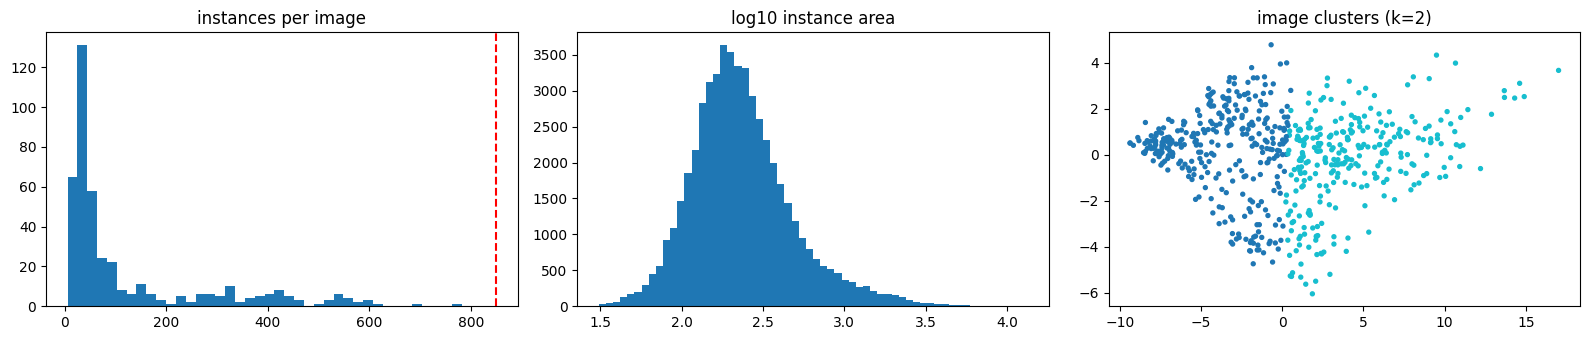

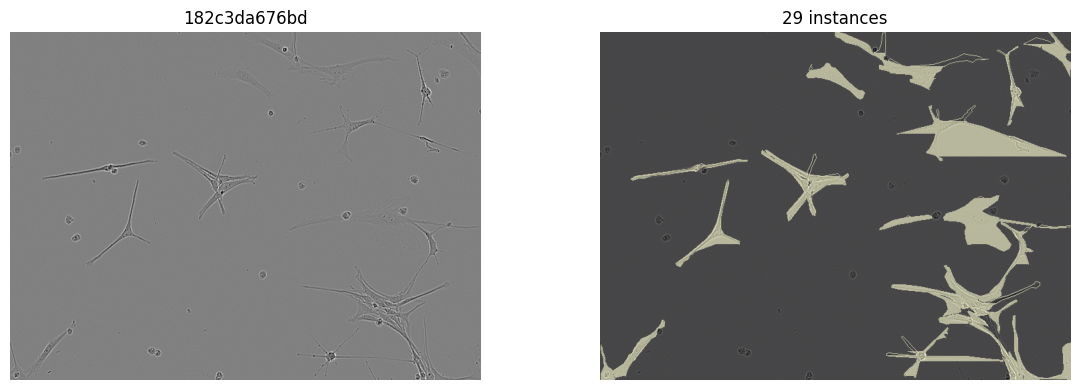

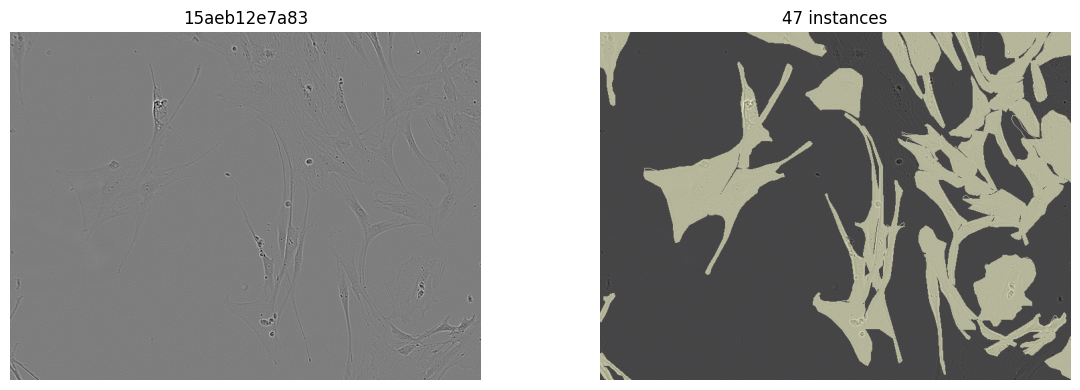

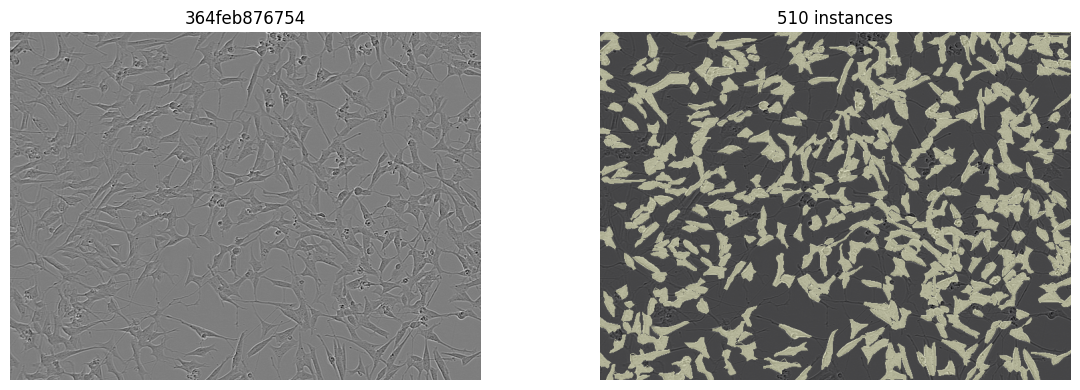

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
axes[0].hist(counts, bins=40)
axes[0].axvline(CFG.BOX_DET_PER_IMG, color="red", linestyle="--")
axes[0].set_title("instances per image")

axes[1].hist(np.log10(areas + 1), bins=60)
axes[1].set_title("log10 instance area")

axes[2].scatter(pca_features[:, 0], pca_features[:, 1], c=cluster_labels, s=8, cmap="tab10")
axes[2].set_title(f"image clusters (k={BEST_K})")

plt.tight_layout()
plt.savefig(ART / "eda_statistics.png", dpi=120)
plt.show()

def show_overlay(image_id):
    image = load_gray01(TRAIN_DIR / f"{image_id}.png")
    union = np.zeros((CFG.IMG_H, CFG.IMG_W), dtype=np.uint8)
    for flat in INST[image_id]:
        union.reshape(-1)[flat] = 1

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].imshow(image, cmap="gray")
    ax[0].set_title(image_id)
    ax[0].axis("off")
    ax[1].imshow(image, cmap="gray")
    ax[1].imshow(union, alpha=0.45, cmap="magma")
    ax[1].set_title(f"{len(INST[image_id])} instances")
    ax[1].axis("off")
    plt.tight_layout()
    plt.show()

sample_ids = [
    min(TRAIN_IDS, key=lambda image_id: abs(len(INST.get(image_id, [])) - np.percentile(counts, p)))
    for p in (25, 50, 95)
]
for sample_id in sample_ids:
    show_overlay(sample_id)


## 7 · Official instance-F1 metric

For each image:

1. compute pairwise mask Dice;
2. greedily select the current highest Dice pair;
3. accept it only when Dice ≥ 0.50;
4. remove the matched prediction and ground-truth mask;
5. calculate `2TP / (2TP + FP + FN)`.

The competition score is the plain mean across images.


In [16]:
from scipy.sparse import csr_matrix

NPIX = CFG.IMG_H * CFG.IMG_W

def sparse_masks(flats, npix):
    if len(flats) == 0:
        return csr_matrix((0, npix), dtype=np.float32)

    indptr = np.zeros(len(flats) + 1, dtype=np.int64)
    indptr[1:] = np.cumsum([len(flat) for flat in flats])
    indices = np.concatenate(flats).astype(np.int64)
    data = np.ones(indices.size, dtype=np.float32)
    return csr_matrix((data, indices, indptr), shape=(len(flats), npix))

def dice_matrix(gt_flats, pred_flats, npix):
    if len(gt_flats) == 0 or len(pred_flats) == 0:
        return np.zeros((len(gt_flats), len(pred_flats)), dtype=np.float32)

    gt_sparse = sparse_masks(gt_flats, npix)
    pred_sparse = sparse_masks(pred_flats, npix)
    intersection = (gt_sparse @ pred_sparse.T).toarray()

    gt_area = np.asarray(gt_sparse.sum(axis=1)).reshape(-1, 1)
    pred_area = np.asarray(pred_sparse.sum(axis=1)).reshape(1, -1)
    return (2.0 * intersection / np.maximum(gt_area + pred_area, 1.0)).astype(np.float32)

def greedy_match(dice, threshold=0.50):
    work = np.asarray(dice, dtype=np.float32).copy()
    if work.size == 0:
        return 0

    tp = 0
    while True:
        flat_index = int(np.argmax(work))
        best = float(work.flat[flat_index])
        if best < threshold:
            break
        gt_index, pred_index = np.unravel_index(flat_index, work.shape)
        tp += 1
        work[gt_index, :] = -1.0
        work[:, pred_index] = -1.0
    return tp

def instance_f1_from_dice(dice, threshold=0.50):
    n_gt, n_pred = dice.shape
    if n_gt == 0 and n_pred == 0:
        return 1.0
    if n_gt == 0 or n_pred == 0:
        return 0.0

    tp = greedy_match(dice, threshold)
    fp = n_pred - tp
    fn = n_gt - tp
    return 2.0 * tp / (2.0 * tp + fp + fn + 1e-8)

def score_dataset_f1(gt_by_id, pred_by_id, npix=NPIX, threshold=0.50, return_per_image=False):
    per_image = {}
    for image_id, gt_flats in gt_by_id.items():
        pred_flats = pred_by_id.get(image_id, [])
        dice = dice_matrix(gt_flats, pred_flats, npix)
        per_image[image_id] = instance_f1_from_dice(dice, threshold)

    mean_score = float(np.mean(list(per_image.values()))) if per_image else 0.0
    return (mean_score, per_image) if return_per_image else mean_score

# Unit tests, including the duplicate-prediction case.
_a = np.array([0, 1, 2], dtype=np.int32)
_b = np.array([10, 11], dtype=np.int32)
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a]}) - 1.0) < 1e-7
assert score_dataset_f1({"x": [_a]}, {"x": []}) == 0.0
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a, _a]}) - (2 / 3)) < 1e-7
assert abs(score_dataset_f1({"x": [_a, _b]}, {"x": [_a, _b]}) - 1.0) < 1e-7
print("official-metric unit tests: passed")


official-metric unit tests: passed


## 8 · Validation split, stratified by image cluster and density


In [17]:
from sklearn.model_selection import train_test_split

labeled_ids = [image_id for image_id in TRAIN_IDS if image_id in INST]
density = np.asarray([len(INST[image_id]) for image_id in labeled_ids])
density_bins = np.digitize(density, np.percentile(density, [33, 66]))

strata = [
    f"{CLUSTER.get(image_id, -1)}_{density_bin}"
    for image_id, density_bin in zip(labeled_ids, density_bins)
]
stratum_counts = Counter(strata)
strata = [label if stratum_counts[label] >= 2 else "rare" for label in strata]

train_ids, val_ids = train_test_split(
    labeled_ids,
    test_size=CFG.VAL_FRACTION,
    random_state=CFG.SEED,
    stratify=strata,
)

if CFG.SMOKE_TEST:
    train_ids = train_ids[:24]
    val_ids = val_ids[:12]

GT_VAL = {image_id: INST[image_id] for image_id in val_ids}

print("train images:", len(train_ids))
print("val images  :", len(val_ids))
print("train instances/image mean:", np.mean([len(INST[x]) for x in train_ids]))
print("val instances/image mean  :", np.mean([len(INST[x]) for x in val_ids]))

STATS["train_ids"] = train_ids
STATS["val_ids"] = val_ids


train images: 360
val images  : 64
train instances/image mean: 126.00277777777778
val instances/image mean  : 120.375


## 9 · Dataset, augmentation, and data loaders


In [18]:
from torch.utils.data import Dataset, DataLoader

class CellDataset(Dataset):
    def __init__(self, ids, image_dir, training):
        self.ids = list(ids)
        self.image_dir = Path(image_dir)
        self.training = bool(training)

    def __len__(self):
        return len(self.ids)

    def augment(self, image, masks):
        if random.random() < CFG.AUG_HFLIP:
            image = image[:, ::-1]
            masks = masks[:, :, ::-1]

        if random.random() < CFG.AUG_VFLIP:
            image = image[::-1, :]
            masks = masks[:, ::-1, :]

        if random.random() < CFG.AUG_ROT90:
            k = random.choice((1, 2, 3))
            image = np.rot90(image, k)
            masks = np.rot90(masks, k, axes=(1, 2))

        image = np.ascontiguousarray(image)
        masks = np.ascontiguousarray(masks)

        if random.random() < CFG.AUG_BRIGHTNESS_CONTRAST:
            contrast = random.uniform(0.85, 1.18)
            brightness = random.uniform(-0.10, 0.10)
            image = np.clip((image - 0.5) * contrast + 0.5 + brightness, 0, 1)

        if random.random() < CFG.AUG_GAMMA:
            image = np.clip(image, 1e-4, 1.0) ** random.uniform(0.75, 1.35)

        if random.random() < CFG.AUG_NOISE:
            sigma = random.uniform(0.005, 0.02)
            image = np.clip(image + np.random.normal(0, sigma, image.shape), 0, 1)

        return image.astype(np.float32), masks

    def __getitem__(self, index):
        image_id = self.ids[index]
        image = load_gray01(self.image_dir / f"{image_id}.png")

        flats = INST[image_id]
        if CFG.MAX_INSTANCES_TRAIN and len(flats) > CFG.MAX_INSTANCES_TRAIN:
            chosen = np.random.choice(len(flats), CFG.MAX_INSTANCES_TRAIN, replace=False)
            flats = [flats[j] for j in chosen]

        masks = np.zeros(
            (len(flats), CFG.IMG_H * CFG.IMG_W),
            dtype=np.uint8,
        )
        for mask_index, flat in enumerate(flats):
            masks[mask_index, flat] = 1
        masks = masks.reshape(len(flats), CFG.IMG_H, CFG.IMG_W)

        if self.training:
            image, masks = self.augment(image, masks)

        height, width = image.shape
        boxes = []
        kept_masks = []

        for mask in masks:
            ys, xs = np.nonzero(mask)
            if ys.size < CFG.MIN_GT_AREA:
                continue
            x0, x1 = xs.min(), xs.max()
            y0, y1 = ys.min(), ys.max()
            if x1 <= x0 or y1 <= y0:
                continue
            boxes.append([x0, y0, x1 + 1, y1 + 1])
            kept_masks.append(mask)

        if kept_masks:
            masks_array = np.stack(kept_masks).astype(np.uint8)
        else:
            masks_array = np.zeros((0, height, width), dtype=np.uint8)

        target = {
            "boxes": torch.as_tensor(np.asarray(boxes, dtype=np.float32).reshape(-1, 4)),
            "labels": torch.ones(len(boxes), dtype=torch.int64),
            "masks": torch.as_tensor(masks_array, dtype=torch.uint8),
            "image_id": torch.tensor([index], dtype=torch.int64),
        }

        tensor = torch.from_numpy(np.ascontiguousarray(image)).unsqueeze(0).repeat(3, 1, 1)
        return tensor, target, image_id

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    CellDataset(train_ids, TRAIN_DIR, training=True),
    batch_size=CFG.BATCH_SIZE,
    shuffle=True,
    num_workers=CFG.NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True,
    persistent_workers=CFG.NUM_WORKERS > 0,
    prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
    drop_last=True,
)

val_loader = DataLoader(
    CellDataset(val_ids, TRAIN_DIR, training=False),
    batch_size=1,
    shuffle=False,
    num_workers=CFG.NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True,
    persistent_workers=False,
)

batch_images, batch_targets, batch_ids = next(iter(train_loader))
print("batch image shapes:", [tuple(image.shape) for image in batch_images])
print("instances:", [len(target["labels"]) for target in batch_targets])
print(
    "mask target memory:",
    f"{sum(target['masks'].numel() for target in batch_targets) / 1e6:.0f} MB uint8",
)


batch image shapes: [(3, 520, 704), (3, 520, 704)]
instances: [31, 34]
mask target memory: 24 MB uint8


## 10 · Mask R-CNN v2 with Dice-aligned mask loss and corrected anchors


In [19]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection import roi_heads as roi_heads_module

ORIGINAL_MASK_LOSS = roi_heads_module.maskrcnn_loss

def maskrcnn_loss_bce_dice(mask_logits, proposals, gt_masks, gt_labels, mask_matched_idxs):
    resolution = mask_logits.shape[-1]

    if sum(int(matched.numel()) for matched in mask_matched_idxs) == 0:
        return mask_logits.sum() * 0.0

    labels = torch.cat(
        [labels_per_image[matched] for labels_per_image, matched in zip(gt_labels, mask_matched_idxs)],
        dim=0,
    )
    targets = torch.cat(
        [
            roi_heads_module.project_masks_on_boxes(masks, proposals_per_image, matched, resolution)
            for masks, proposals_per_image, matched in zip(gt_masks, proposals, mask_matched_idxs)
        ],
        dim=0,
    )

    if targets.numel() == 0:
        return mask_logits.sum() * 0.0

    row_index = torch.arange(labels.shape[0], device=labels.device)
    logits = mask_logits[row_index, labels].float()
    targets = targets.float()

    bce = F.binary_cross_entropy_with_logits(logits, targets)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum(dim=(1, 2))
    denominator = probabilities.sum(dim=(1, 2)) + targets.sum(dim=(1, 2))
    dice_loss = 1.0 - (2.0 * intersection + 1.0) / (denominator + 1.0)

    return CFG.BCE_W * bce + CFG.DICE_W * dice_loss.mean()

roi_heads_module.maskrcnn_loss = (
    maskrcnn_loss_bce_dice if CFG.MASK_LOSS == "bce+dice" else ORIGINAL_MASK_LOSS
)

def build_model():
    common = {
        "box_detections_per_img": CFG.BOX_DET_PER_IMG,
        "min_size": min(CFG.MIN_SIZE_TRAIN),
        "max_size": CFG.MAX_SIZE,
        "rpn_batch_size_per_image": CFG.RPN_BATCH_PER_IMG,
        "box_batch_size_per_image": CFG.BOX_BATCH_PER_IMG,
    }

    if CFG.ARCH == "v2":
        from torchvision.models.detection import (
            maskrcnn_resnet50_fpn_v2,
            MaskRCNN_ResNet50_FPN_V2_Weights,
        )
        constructor = maskrcnn_resnet50_fpn_v2
        coco_weights = MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1
    else:
        from torchvision.models.detection import (
            maskrcnn_resnet50_fpn,
            MaskRCNN_ResNet50_FPN_Weights,
        )
        constructor = maskrcnn_resnet50_fpn
        coco_weights = MaskRCNN_ResNet50_FPN_Weights.COCO_V1

    from torchvision.models import ResNet50_Weights

    if CFG.WEIGHTS_MODE == "coco":
        model = constructor(
            weights=coco_weights,
            trainable_backbone_layers=CFG.TRAINABLE_BACKBONE_LAYERS,
            **common,
        )
        weight_description = "COCO detector"
    elif CFG.WEIGHTS_MODE == "imagenet_bb":
        model = constructor(
            weights=None,
            weights_backbone=ResNet50_Weights.IMAGENET1K_V1,
            trainable_backbone_layers=CFG.TRAINABLE_BACKBONE_LAYERS,
            **common,
        )
        weight_description = "ImageNet backbone only"
    else:
        raise ValueError(f"Unknown WEIGHTS_MODE: {CFG.WEIGHTS_MODE}")

    box_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(box_features, 2)

    mask_features = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(mask_features, 256, 2)

    ratios = tuple(CFG.ASPECT_RATIOS)
    model.rpn.anchor_generator = AnchorGenerator(
        sizes=tuple(CFG.ANCHOR_SIZES),
        aspect_ratios=tuple(ratios for _ in CFG.ANCHOR_SIZES),
    )

    model.roi_heads.nms_thresh = CFG.BOX_NMS_THR
    model.transform.min_size = tuple(CFG.MIN_SIZE_TRAIN)
    model.transform.max_size = CFG.MAX_SIZE

    if CFG.NORMALIZE_WITH_DATASET_STATS:
        model.transform.image_mean = [DS_MEAN] * 3
        model.transform.image_std = [DS_STD] * 3

    print("weights       :", weight_description)
    print("mask loss     :", CFG.MASK_LOSS)
    print("anchors       :", model.rpn.anchor_generator.sizes)
    print("ratios        :", model.rpn.anchor_generator.aspect_ratios[0])
    print("normalization :", model.transform.image_mean, model.transform.image_std)
    print("box NMS       :", model.roi_heads.nms_thresh)
    print("detections/img:", model.roi_heads.detections_per_img)
    return model

model = build_model().to(DEVICE)
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"trainable parameters: {trainable_parameters / 1e6:.1f}M")


Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 177MB/s]  


weights       : COCO detector
mask loss     : bce+dice
anchors       : ((20,), (24,), (28,), (40,), (92,))
ratios        : (0.62, 1.0, 1.58)
normalization : [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
box NMS       : 0.6
detections/img: 850
trainable parameters: 45.9M


## 11 · Inference helpers, cached cropped masks, and checkpoint evaluation


In [20]:
def autocast_context():
    try:
        return torch.amp.autocast("cuda", enabled=CFG.AMP)
    except Exception:
        return torch.cuda.amp.autocast(enabled=CFG.AMP)

def set_inference_config(model, score_threshold, max_detections):
    model.roi_heads.score_thresh = float(score_threshold)
    model.roi_heads.detections_per_img = int(max_detections)
    model.roi_heads.nms_thresh = float(CFG.BOX_NMS_THR)
    model.rpn._pre_nms_top_n["testing"] = int(CFG.RPN_PRE_TEST)
    model.rpn._post_nms_top_n["testing"] = int(CFG.RPN_POST_TEST)
    model.transform.min_size = (CFG.MIN_SIZE_TEST,)

@torch.no_grad()
def cache_predictions(model, ids, image_dir, progress_every=25):
    model.eval()
    set_inference_config(model, CFG.CACHE_SCORE_THR, CFG.CACHE_MAX_DET)
    image_dir = Path(image_dir)
    cache = {}

    for position, image_id in enumerate(ids, 1):
        image = load_gray01(image_dir / f"{image_id}.png")
        tensor = (
            torch.from_numpy(np.ascontiguousarray(image))
            .unsqueeze(0)
            .repeat(3, 1, 1)
            .to(DEVICE, non_blocking=True)
        )

        try:
            with autocast_context():
                output = model([tensor])[0]
        except RuntimeError as error:
            if "out of memory" not in str(error).lower():
                raise
            print(f"OOM on {image_id}; retrying after clearing cache")
            del tensor
            gc.collect()
            torch.cuda.empty_cache()
            image = load_gray01(image_dir / f"{image_id}.png")
            tensor = torch.from_numpy(image).unsqueeze(0).repeat(3, 1, 1).to(DEVICE)
            with autocast_context():
                output = model([tensor])[0]

        scores = output["scores"].detach().float().cpu().numpy()
        boxes = output["boxes"].detach().float().cpu().numpy()

        # Convert on GPU before transfer: 4x less host traffic than float32.
        masks_u8 = (
            output["masks"][:, 0]
            .detach()
            .clamp_(0, 1)
            .mul_(255)
            .to(torch.uint8)
            .cpu()
            .numpy()
        )

        entries = []
        for score, box, mask_u8 in zip(scores, boxes, masks_u8):
            x0, y0, x1, y1 = box
            x0 = max(0, int(math.floor(x0)) - 2)
            y0 = max(0, int(math.floor(y0)) - 2)
            x1 = min(CFG.IMG_W, int(math.ceil(x1)) + 2)
            y1 = min(CFG.IMG_H, int(math.ceil(y1)) + 2)
            if x1 <= x0 or y1 <= y0:
                continue

            crop = np.ascontiguousarray(mask_u8[y0:y1, x0:x1])
            if crop.size == 0 or crop.max() == 0:
                continue
            entries.append((float(score), y0, x0, crop))

        entries.sort(key=lambda item: -item[0])
        cache[image_id] = entries

        del output, masks_u8, tensor
        if position % progress_every == 0 or position == len(ids):
            print(f"  cached {position}/{len(ids)}", flush=True)

    return cache

def build_instances(entries, mask_threshold, min_area, height, width, allow_overlap):
    occupied = np.zeros(height * width, dtype=bool) if not allow_overlap else None
    instances = []

    for score, y0, x0, crop in entries:
        binary = crop > int(round(mask_threshold * 255))
        ys, xs = np.nonzero(binary)
        if ys.size == 0:
            continue

        flat = (ys + y0).astype(np.int64) * width + (xs + x0)
        if occupied is not None:
            flat = flat[~occupied[flat]]

        if flat.size < min_area:
            continue

        if occupied is not None:
            occupied[flat] = True

        instances.append((float(score), flat.astype(np.int32)))

    return instances

def evaluate_cached_predictions(
    cache,
    ids,
    gt_by_id,
    mask_threshold,
    min_area,
    allow_overlap,
    score_grid,
):
    built = {
        image_id: build_instances(
            cache[image_id],
            mask_threshold,
            min_area,
            CFG.IMG_H,
            CFG.IMG_W,
            allow_overlap,
        )
        for image_id in ids
    }

    matrices = {}
    for image_id in ids:
        pred_flats = [flat for _, flat in built[image_id]]
        scores = np.asarray([score for score, _ in built[image_id]], dtype=np.float32)
        matrices[image_id] = (
            dice_matrix(gt_by_id[image_id], pred_flats, NPIX),
            scores,
        )

    rows = []
    for score_threshold in score_grid:
        per_image = {}
        predictions = []

        for image_id in ids:
            dice, scores = matrices[image_id]
            n_keep = int((scores >= score_threshold).sum())
            score = instance_f1_from_dice(
                dice[:, :n_keep],
                CFG.DICE_MATCH_THR,
            )
            per_image[image_id] = score
            predictions.append(n_keep)

        rows.append(
            {
                "score_thr": float(score_threshold),
                "f1": float(np.mean(list(per_image.values()))),
                "mean_predictions": float(np.mean(predictions)),
                "per_image": per_image,
            }
        )

    return rows, built, matrices

@torch.no_grad()
def quick_evaluate_checkpoint(model):
    cache = cache_predictions(model, val_ids, TRAIN_DIR, progress_every=max(len(val_ids), 1))
    results, _, _ = evaluate_cached_predictions(
        cache=cache,
        ids=val_ids,
        gt_by_id=GT_VAL,
        mask_threshold=CFG.EVAL_MASK_THR,
        min_area=CFG.EVAL_MIN_AREA,
        allow_overlap=False,
        score_grid=CFG.EVAL_SCORE_GRID,
    )
    best = max(results, key=lambda row: row["f1"])
    del cache
    gc.collect()
    torch.cuda.empty_cache()
    return best


## 12 · Optimizer, AMP scaler, cosine schedule, and resume state


In [21]:
backbone_parameters = [
    parameter
    for name, parameter in model.named_parameters()
    if parameter.requires_grad and name.startswith("backbone")
]
head_parameters = [
    parameter
    for name, parameter in model.named_parameters()
    if parameter.requires_grad and not name.startswith("backbone")
]

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_parameters, "lr": CFG.LR * CFG.BACKBONE_LR_MULT},
        {"params": head_parameters, "lr": CFG.LR},
    ],
    weight_decay=CFG.WEIGHT_DECAY,
)

optimizer_steps_per_epoch = max(1, math.ceil(len(train_loader) / CFG.ACCUM_STEPS))
total_optimizer_steps = optimizer_steps_per_epoch * CFG.EPOCHS

def learning_rate_multiplier(step):
    if step < CFG.WARMUP_STEPS:
        return (step + 1) / max(CFG.WARMUP_STEPS, 1)
    progress = (step - CFG.WARMUP_STEPS) / max(
        total_optimizer_steps - CFG.WARMUP_STEPS,
        1,
    )
    progress = min(max(progress, 0.0), 1.0)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, learning_rate_multiplier)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=CFG.AMP)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=CFG.AMP)

BEST_PATH = CKPT / "best.pt"
LAST_PATH = CKPT / "last.pt"

start_epoch = 1
best_score = -1.0
training_log = []

if LAST_PATH.exists():
    checkpoint = torch.load(LAST_PATH, map_location="cpu")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    start_epoch = int(checkpoint["epoch"]) + 1
    best_score = float(checkpoint["best_score"])
    training_log = checkpoint.get("training_log", [])
    print(f"resumed from epoch {checkpoint['epoch']} with best F1={best_score:.4f}")
else:
    print("starting a fresh run")

print("optimizer steps/epoch:", optimizer_steps_per_epoch)
print("total optimizer steps:", total_optimizer_steps)
print("warmup steps:", CFG.WARMUP_STEPS)


starting a fresh run
optimizer steps/epoch: 90
total optimizer steps: 2340
warmup steps: 250


## 13 · Full training with mixed precision and wall-clock protection


In [22]:
epoch_durations = []

for epoch in range(start_epoch, CFG.EPOCHS + 1):
    estimated_next_epoch = float(np.mean(epoch_durations[-3:])) if epoch_durations else 0.0
    remaining_budget = CFG.TOTAL_BUDGET_SEC - elapsed_seconds()

    if epoch_durations and remaining_budget < estimated_next_epoch + CFG.RESERVE_SEC:
        print(
            f"Stopping before epoch {epoch}: remaining {format_duration(remaining_budget)}, "
            f"estimated epoch {format_duration(estimated_next_epoch)}, "
            f"reserve {format_duration(CFG.RESERVE_SEC)}"
        )
        break

    model.train()
    model.transform.min_size = tuple(CFG.MIN_SIZE_TRAIN)
    epoch_start = time.time()
    accumulated = defaultdict(float)
    valid_iterations = 0

    optimizer.zero_grad(set_to_none=True)

    for iteration, (images, targets, _) in enumerate(train_loader, 1):
        images = [image.to(DEVICE, non_blocking=True) for image in images]
        targets = [
            {
                key: value.to(DEVICE, non_blocking=True) if torch.is_tensor(value) else value
                for key, value in target.items()
            }
            for target in targets
        ]

        if any(target["boxes"].shape[0] == 0 for target in targets):
            continue

        with autocast_context():
            loss_dict = model(images, targets)
            total_loss = sum(loss_dict.values())

        if not torch.isfinite(total_loss):
            print(f"  non-finite loss at iteration {iteration}; skipped")
            optimizer.zero_grad(set_to_none=True)
            continue

        scaler.scale(total_loss / CFG.ACCUM_STEPS).backward()
        valid_iterations += 1

        for name, value in loss_dict.items():
            accumulated[name] += float(value.detach())
        accumulated["total"] += float(total_loss.detach())

        should_step = (
            iteration % CFG.ACCUM_STEPS == 0
            or iteration == len(train_loader)
        )
        if should_step:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        if iteration % 50 == 0:
            denom = max(valid_iterations, 1)
            print(
                f"  epoch {epoch:02d} iter {iteration:03d}/{len(train_loader)} "
                f"loss={accumulated['total'] / denom:.4f} "
                f"mask={accumulated['loss_mask'] / denom:.4f} "
                f"lr={scheduler.get_last_lr()[-1]:.2e} "
                f"{(time.time() - epoch_start) / iteration:.2f}s/iter",
                flush=True,
            )

    epoch_seconds = time.time() - epoch_start
    epoch_durations.append(epoch_seconds)
    denom = max(valid_iterations, 1)

    row = {
        "epoch": epoch,
        **{name: value / denom for name, value in accumulated.items()},
        "lr": scheduler.get_last_lr()[-1],
        "train_seconds": round(epoch_seconds, 1),
    }

    evaluate_now = (
        epoch >= CFG.EVAL_START_EPOCH
        and (
            epoch >= CFG.EVAL_DENSE_FROM
            or epoch % CFG.EVAL_EVERY_EARLY == 0
        )
    )

    if evaluate_now:
        evaluation_start = time.time()
        evaluation = quick_evaluate_checkpoint(model)
        row["val_f1"] = evaluation["f1"]
        row["val_score_thr"] = evaluation["score_thr"]
        row["val_mean_predictions"] = evaluation["mean_predictions"]
        row["eval_seconds"] = round(time.time() - evaluation_start, 1)

        if evaluation["f1"] > best_score:
            best_score = float(evaluation["f1"])
            torch.save(
                {
                    "model": model.state_dict(),
                    "epoch": epoch,
                    "score": best_score,
                    "score_threshold": evaluation["score_thr"],
                    "cfg": {k: str(v) for k, v in vars(CFG).items() if k.isupper()},
                },
                BEST_PATH,
            )
            row["saved_best"] = True

    training_log.append(row)

    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "epoch": epoch,
            "best_score": best_score,
            "training_log": training_log,
        },
        LAST_PATH,
    )
    pd.DataFrame(training_log).to_csv(ART / "training_log.csv", index=False)

    print(
        f"[epoch {epoch:02d}] "
        + " ".join(
            f"{key}={value:.4f}" if isinstance(value, float) else f"{key}={value}"
            for key, value in row.items()
        ),
        flush=True,
    )

    gc.collect()
    torch.cuda.empty_cache()

# If the time guard stopped before the first scheduled evaluation, preserve the latest model.
if not BEST_PATH.exists():
    print("No evaluated best checkpoint exists; saving the current model as best.pt")
    torch.save(
        {
            "model": model.state_dict(),
            "epoch": training_log[-1]["epoch"] if training_log else 0,
            "score": best_score,
            "cfg": {k: str(v) for k, v in vars(CFG).items() if k.isupper()},
        },
        BEST_PATH,
    )

print("\nbest validation F1:", best_score)
print("elapsed:", format_duration(elapsed_seconds()))
print(pd.DataFrame(training_log).tail(10).to_string(index=False))
STATS["best_val_score_during_training"] = float(best_score)


  epoch 01 iter 050/180 loss=3.6018 mask=1.6984 lr=1.56e-05 10.39s/iter
  epoch 01 iter 100/180 loss=2.9353 mask=1.3021 lr=3.06e-05 7.32s/iter
  epoch 01 iter 150/180 loss=2.5743 mask=1.0917 lr=4.56e-05 5.47s/iter
[epoch 01] epoch=1 loss_classifier=0.3768 loss_box_reg=0.3135 loss_mask=1.0095 loss_objectness=0.5987 loss_rpn_box_reg=0.1251 total=2.4236 lr=0.0001 train_seconds=849.4000
  epoch 02 iter 050/180 loss=1.5188 mask=0.5565 lr=6.96e-05 1.12s/iter
  epoch 02 iter 100/180 loss=1.5347 mask=0.5604 lr=8.46e-05 1.03s/iter
  epoch 02 iter 150/180 loss=1.5176 mask=0.5500 lr=9.96e-05 0.96s/iter
[epoch 02] epoch=2 loss_classifier=0.3196 loss_box_reg=0.4281 loss_mask=0.5480 loss_objectness=0.1371 loss_rpn_box_reg=0.0920 total=1.5248 lr=0.0001 train_seconds=162.4000
  epoch 03 iter 050/180 loss=1.5188 mask=0.5509 lr=1.24e-04 0.79s/iter
  epoch 03 iter 100/180 loss=1.5106 mask=0.5379 lr=1.39e-04 0.73s/iter
  epoch 03 iter 150/180 loss=1.4810 mask=0.5273 lr=1.50e-04 0.73s/iter
  cached 64/64
[

## 14 · Load the best checkpoint and cache validation predictions once


In [23]:
best_checkpoint = torch.load(BEST_PATH, map_location="cpu")
model.load_state_dict(best_checkpoint["model"])
model.to(DEVICE).eval()
print(
    "loaded best checkpoint:",
    "epoch", best_checkpoint.get("epoch"),
    "score", best_checkpoint.get("score"),
)

validation_cache_start = time.time()
VAL_CACHE = cache_predictions(model, val_ids, TRAIN_DIR)
print(
    f"validation cache completed in {format_duration(time.time() - validation_cache_start)}; "
    f"mean raw detections/image={np.mean([len(v) for v in VAL_CACHE.values()]):.1f}"
)


loaded best checkpoint: epoch 24 score 0.7796296060583032
  cached 25/64
  cached 50/64
  cached 64/64
validation cache completed in 0h 00m; mean raw detections/image=558.0


## 15 · Full F1 post-processing sweep, including overlap handling


In [24]:
summary_rows = []
per_image_rows = []

for mask_threshold in CFG.SWEEP_MASK_THR:
    for min_area in MIN_AREA_GRID:
        for allow_overlap in CFG.SWEEP_ALLOW_OVERLAP:
            results, _, _ = evaluate_cached_predictions(
                cache=VAL_CACHE,
                ids=val_ids,
                gt_by_id=GT_VAL,
                mask_threshold=mask_threshold,
                min_area=min_area,
                allow_overlap=allow_overlap,
                score_grid=CFG.SWEEP_SCORE_THR,
            )

            for result in results:
                summary_rows.append(
                    {
                        "mask_thr": float(mask_threshold),
                        "min_area": int(min_area),
                        "allow_overlap": bool(allow_overlap),
                        "score_thr": float(result["score_thr"]),
                        "f1": float(result["f1"]),
                        "mean_predictions": float(result["mean_predictions"]),
                    }
                )

                for image_id, image_f1 in result["per_image"].items():
                    per_image_rows.append(
                        {
                            "id": image_id,
                            "cluster": int(CLUSTER.get(image_id, -1)),
                            "mask_thr": float(mask_threshold),
                            "min_area": int(min_area),
                            "allow_overlap": bool(allow_overlap),
                            "score_thr": float(result["score_thr"]),
                            "f1": float(image_f1),
                        }
                    )

sweep = pd.DataFrame(summary_rows).sort_values("f1", ascending=False).reset_index(drop=True)
per_image_sweep = pd.DataFrame(per_image_rows)

sweep.to_csv(ART / "sweep_results.csv", index=False)
per_image_sweep.to_csv(ART / "sweep_per_image.csv", index=False)

print(sweep.head(15).to_string(index=False))

best_global_row = sweep.iloc[0]
GLOBAL_POST = {
    "mask_thr": float(best_global_row.mask_thr),
    "min_area": int(best_global_row.min_area),
    "allow_overlap": bool(best_global_row.allow_overlap),
    "score_thr": float(best_global_row.score_thr),
}
GLOBAL_F1 = float(best_global_row.f1)

print("\nglobal post-processing:", GLOBAL_POST)
print("global validation F1:", GLOBAL_F1)


 mask_thr  min_area  allow_overlap  score_thr       f1  mean_predictions
      0.5       103          False       0.26 0.790872        107.156250
      0.5       103          False       0.28 0.790765        103.250000
      0.6       103          False       0.28 0.790528        102.906250
      0.6       103          False       0.26 0.790486        106.796875
      0.5       103          False       0.30 0.790406         99.281250
      0.6        87          False       0.28 0.790367        104.875000
      0.6        87          False       0.30 0.790206        100.703125
      0.6       103          False       0.30 0.790134         98.937500
      0.5       103          False       0.24 0.789995        111.109375
      0.6        87          False       0.26 0.789799        108.953125
      0.6       103          False       0.24 0.789489        110.750000
      0.5        87          False       0.30 0.789460        100.984375
      0.4       103          False       0.30 0.788

In [25]:
# Cluster-specific thresholds reuse the already-computed per-image sweep.
cluster_posts = {}
cluster_best_rows = []

parameter_columns = ["mask_thr", "min_area", "allow_overlap", "score_thr"]

for cluster_id in sorted(per_image_sweep["cluster"].unique()):
    cluster_image_ids = [
        image_id for image_id in val_ids
        if CLUSTER.get(image_id, -1) == cluster_id
    ]
    if len(cluster_image_ids) < CFG.PER_CLUSTER_MIN_VAL:
        continue

    cluster_scores = (
        per_image_sweep[per_image_sweep["cluster"] == cluster_id]
        .groupby(parameter_columns, as_index=False)["f1"]
        .mean()
        .sort_values("f1", ascending=False)
    )
    best = cluster_scores.iloc[0]
    post = {
        "mask_thr": float(best.mask_thr),
        "min_area": int(best.min_area),
        "allow_overlap": bool(best.allow_overlap),
        "score_thr": float(best.score_thr),
    }
    cluster_posts[int(cluster_id)] = post
    cluster_best_rows.append(
        {
            "cluster": int(cluster_id),
            "n_val": len(cluster_image_ids),
            "f1": float(best.f1),
            **post,
        }
    )

if cluster_best_rows:
    print(pd.DataFrame(cluster_best_rows).to_string(index=False))
else:
    print("No cluster had enough validation images for separate thresholds.")

selected_cluster_scores = []
for image_id in val_ids:
    cluster_id = int(CLUSTER.get(image_id, -1))
    post = cluster_posts.get(cluster_id, GLOBAL_POST)

    mask = (
        (per_image_sweep["id"] == image_id)
        & np.isclose(per_image_sweep["mask_thr"], post["mask_thr"])
        & (per_image_sweep["min_area"] == post["min_area"])
        & (per_image_sweep["allow_overlap"] == post["allow_overlap"])
        & np.isclose(per_image_sweep["score_thr"], post["score_thr"])
    )
    matches = per_image_sweep.loc[mask, "f1"]
    if len(matches):
        selected_cluster_scores.append(float(matches.iloc[0]))

CLUSTER_F1 = (
    float(np.mean(selected_cluster_scores))
    if len(selected_cluster_scores) == len(val_ids)
    else float("-inf")
)
cluster_gain = CLUSTER_F1 - GLOBAL_F1

USE_CLUSTER_POST = (
    CFG.PER_CLUSTER_THRESHOLDS is True
    or (
        CFG.PER_CLUSTER_THRESHOLDS == "auto"
        and cluster_posts
        and cluster_gain >= CFG.PER_CLUSTER_MIN_GAIN
    )
)

print("\nglobal F1 :", GLOBAL_F1)
print("cluster F1:", CLUSTER_F1)
print("gain       :", cluster_gain)
print("use cluster thresholds:", USE_CLUSTER_POST)

STATS["global_post"] = GLOBAL_POST
STATS["global_f1"] = GLOBAL_F1
STATS["cluster_posts"] = {str(k): v for k, v in cluster_posts.items()}
STATS["cluster_f1"] = CLUSTER_F1
STATS["use_cluster_post"] = bool(USE_CLUSTER_POST)


 cluster  n_val       f1  mask_thr  min_area  allow_overlap  score_thr
       0     34 0.759186       0.5       103          False       0.26
       1     30 0.828367       0.6        87          False       0.28

global F1 : 0.7908722560808787
cluster F1: 0.7916145402701842
gain       : 0.0007422841893054422
use cluster thresholds: False


## 16 · Prediction visualizations on validation images


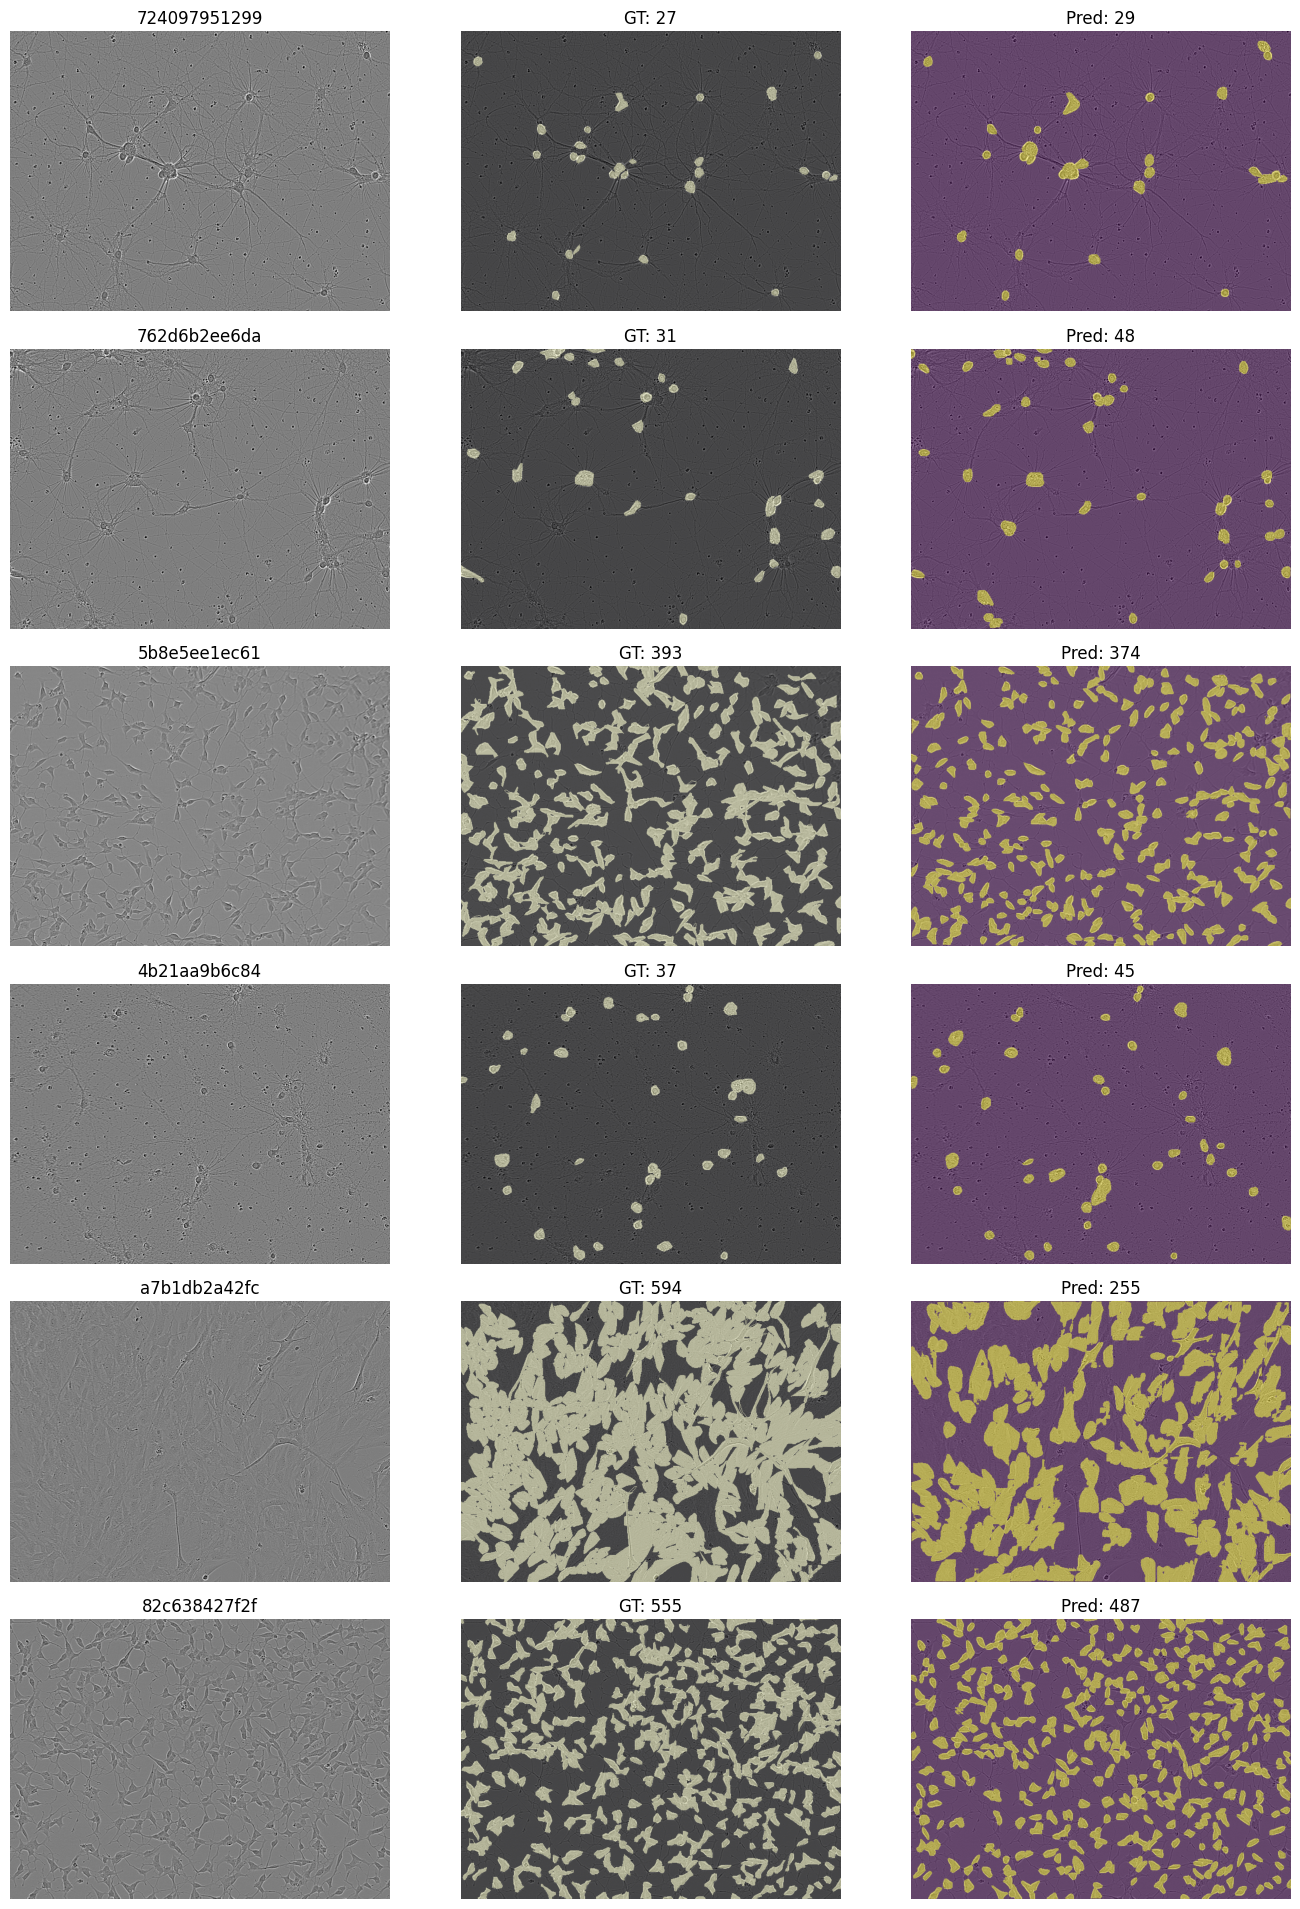

In [26]:
def entries_to_instances(image_id, post):
    built = build_instances(
        VAL_CACHE[image_id],
        post["mask_thr"],
        post["min_area"],
        CFG.IMG_H,
        CFG.IMG_W,
        post["allow_overlap"],
    )
    return [flat for score, flat in built if score >= post["score_thr"]]

visual_ids = val_ids[:6]
fig, axes = plt.subplots(len(visual_ids), 3, figsize=(14, 3.2 * len(visual_ids)))
if len(visual_ids) == 1:
    axes = np.asarray([axes])

for row_index, image_id in enumerate(visual_ids):
    post = (
        cluster_posts.get(int(CLUSTER.get(image_id, -1)), GLOBAL_POST)
        if USE_CLUSTER_POST
        else GLOBAL_POST
    )
    predictions = entries_to_instances(image_id, post)

    image = load_gray01(TRAIN_DIR / f"{image_id}.png")
    gt_union = np.zeros(NPIX, dtype=np.uint8)
    pred_union = np.zeros(NPIX, dtype=np.uint8)
    for flat in GT_VAL[image_id]:
        gt_union[flat] = 1
    for flat in predictions:
        pred_union[flat] = 1

    axes[row_index, 0].imshow(image, cmap="gray")
    axes[row_index, 0].set_title(image_id)
    axes[row_index, 1].imshow(image, cmap="gray")
    axes[row_index, 1].imshow(gt_union.reshape(CFG.IMG_H, CFG.IMG_W), alpha=0.45, cmap="magma")
    axes[row_index, 1].set_title(f"GT: {len(GT_VAL[image_id])}")
    axes[row_index, 2].imshow(image, cmap="gray")
    axes[row_index, 2].imshow(pred_union.reshape(CFG.IMG_H, CFG.IMG_W), alpha=0.45, cmap="viridis")
    axes[row_index, 2].set_title(f"Pred: {len(predictions)}")

    for axis in axes[row_index]:
        axis.axis("off")

plt.tight_layout()
plt.savefig(ART / "validation_predictions.png", dpi=120)
plt.show()


## 17 · Test inference and final submission


In [27]:
if elapsed_seconds() > CFG.TOTAL_BUDGET_SEC - 10 * 60:
    print("Warning: less than 10 minutes remain in the configured budget; starting test inference immediately.")

test_cache_start = time.time()
TEST_CACHE = cache_predictions(model, TEST_IDS, TEST_DIR)
print("test cache time:", format_duration(time.time() - test_cache_start))

submission_rows = []
prediction_counts = []
fallback_count = 0

for image_id in TEST_IDS:
    cluster_id = int(CLUSTER.get(image_id, -1))
    post = (
        cluster_posts.get(cluster_id, GLOBAL_POST)
        if USE_CLUSTER_POST
        else GLOBAL_POST
    )

    built = build_instances(
        TEST_CACHE[image_id],
        post["mask_thr"],
        post["min_area"],
        CFG.IMG_H,
        CFG.IMG_W,
        post["allow_overlap"],
    )
    instances = [
        flat
        for score, flat in built
        if score >= post["score_thr"]
    ]

    # An actual top model detection may help; an invented placeholder mask cannot.
    if not instances and CFG.FALLBACK_TO_TOP_DETECTION and TEST_CACHE[image_id]:
        fallback_built = build_instances(
            TEST_CACHE[image_id],
            mask_threshold=min(0.30, post["mask_thr"]),
            min_area=0,
            height=CFG.IMG_H,
            width=CFG.IMG_W,
            allow_overlap=False,
        )
        if fallback_built:
            instances = [fallback_built[0][1]]
            fallback_count += 1

    prediction_counts.append(len(instances))

    if not instances:
        submission_rows.append((image_id, "-1"))
    else:
        for flat in instances:
            mask = np.zeros(NPIX, dtype=np.uint8)
            mask[flat] = 1
            submission_rows.append((image_id, rle_encode(mask)))

submission = pd.DataFrame(submission_rows, columns=[ID_COL, ANN_COL])
submission.insert(0, CFG.SUB_INDEX_COL, np.arange(len(submission), dtype=np.int64))

output_path = Path("/kaggle/working/submission.csv")
submission.to_csv(output_path, index=False)
shutil.copy(output_path, ART / "submission.csv")

print("submission path   :", output_path)
print("submission columns:", submission.columns.tolist())
print("submission rows   :", len(submission))
print("fallback images   :", fallback_count)
print(
    "predictions/image:",
    {
        "mean": float(np.mean(prediction_counts)),
        "min": int(np.min(prediction_counts)),
        "max": int(np.max(prediction_counts)),
    },
)
print(submission.head(5).to_string(index=False))

assert submission.columns.tolist() == [CFG.SUB_INDEX_COL, ID_COL, ANN_COL]
assert set(submission[ID_COL].astype(str)) == set(TEST_IDS)
assert submission[CFG.SUB_INDEX_COL].is_unique
assert submission[ANN_COL].notna().all()

STATS["test_pred_counts"] = {
    "mean": float(np.mean(prediction_counts)),
    "min": int(np.min(prediction_counts)),
    "max": int(np.max(prediction_counts)),
}
STATS["fallback_images"] = int(fallback_count)


  cached 25/182
  cached 50/182
  cached 75/182
  cached 100/182
  cached 125/182
  cached 150/182
  cached 175/182
  cached 182/182
test cache time: 0h 02m
submission path   : /kaggle/working/submission.csv
submission columns: ['idx', 'id', 'annotation']
submission rows   : 18466
fallback images   : 0
predictions/image: {'mean': 101.46153846153847, 'min': 16, 'max': 476}
 idx           id                                                                                                                                                                                       annotation
   0 0030fd0e6378 92712 3 93415 5 94118 7 94822 9 95526 10 96230 11 96934 12 97638 13 98342 14 99046 14 99750 15 100455 14 101159 14 101863 13 102567 13 103271 13 103975 13 104679 12 105383 11 106088 9 106793 5
   1 0030fd0e6378         258370 2 259074 4 259778 6 260482 9 261186 11 261890 12 262594 14 263298 15 264002 16 264706 17 265410 18 266114 19 266818 20 267524 18 268230 17 268936 15 269641 14 270347 12 2

## 18 · Final report and artifacts


In [28]:
STATS["cfg"] = {
    key: str(value)
    for key, value in vars(CFG).items()
    if key.isupper()
}
STATS["training_log"] = training_log
STATS["elapsed_seconds"] = float(elapsed_seconds())

with open(ART / "run_stats.json", "w") as file:
    json.dump(STATS, file, indent=2, default=str)

report_lines = [
    "# Stage 2 Run Report",
    "",
    f"- Architecture: {CFG.ARCH}",
    f"- Weights: {CFG.WEIGHTS_MODE}",
    f"- Mask loss: {CFG.MASK_LOSS}",
    f"- Official metric: per-image instance F1 at Dice ≥ {CFG.DICE_MATCH_THR}",
    f"- Train/validation images: {len(train_ids)}/{len(val_ids)}",
    f"- Detection capacity: {CFG.BOX_DET_PER_IMG}",
    f"- Anchors: {CFG.ANCHOR_SIZES}",
    f"- Anchor scale correction: {STATS['anchor_scale']:.3f}",
    f"- Best checkpoint F1 during training: {STATS.get('best_val_score_during_training')}",
    f"- Best global sweep F1: {GLOBAL_F1:.6f}",
    f"- Global post-processing: {GLOBAL_POST}",
    f"- Cluster post-processing used: {USE_CLUSTER_POST}",
    f"- Cluster validation F1: {CLUSTER_F1}",
    f"- Test predictions/image: {STATS['test_pred_counts']}",
    f"- Fallback images: {STATS['fallback_images']}",
    f"- Total elapsed: {format_duration(elapsed_seconds())}",
    "",
    "## Submit",
    "",
    "`/kaggle/working/submission.csv`",
]

report_text = "\n".join(report_lines)
(ART / "REPORT.md").write_text(report_text)
print(report_text)

print("\nArtifacts:")
for path in sorted(ART.iterdir()):
    print(" ", path.name)


# Stage 2 Run Report

- Architecture: v2
- Weights: coco
- Mask loss: bce+dice
- Official metric: per-image instance F1 at Dice ≥ 0.5
- Train/validation images: 360/64
- Detection capacity: 850
- Anchors: ((20,), (24,), (28,), (40,), (92,))
- Anchor scale correction: 1.523
- Best checkpoint F1 during training: 0.7796296060583032
- Best global sweep F1: 0.790872
- Global post-processing: {'mask_thr': 0.5, 'min_area': 103, 'allow_overlap': False, 'score_thr': 0.26}
- Cluster post-processing used: False
- Cluster validation F1: 0.7916145402701842
- Test predictions/image: {'mean': 101.46153846153847, 'min': 16, 'max': 476}
- Fallback images: 0
- Total elapsed: 1h 22m

## Submit

`/kaggle/working/submission.csv`

Artifacts:
  REPORT.md
  eda_statistics.png
  run_stats.json
  submission.csv
  sweep_per_image.csv
  sweep_results.csv
  training_log.csv
  validation_predictions.png
